In [1]:
import os
import json

os.environ['KAGGLE_USERNAME'] = "chandramoulibandaru"
os.environ['KAGGLE_KEY'] = "KGAT_4eed677cb21afe63d661c7c029b2a68a"

os.makedirs('/root/.kaggle', exist_ok=True)
with open('/root/.kaggle/kaggle.json', 'w') as f:
    json.dump({"username": "chandramoulibandaru", "key": "KGAT_4eed677cb21afe63d661c7c029b2a68a"}, f)

os.chmod('/root/.kaggle/kaggle.json', 0o600)



In [2]:
!kaggle datasets download karagwaanntreasure/plant-disease-detection

Dataset URL: https://www.kaggle.com/datasets/karagwaanntreasure/plant-disease-detection
License(s): MIT
100% 534M/534M [00:28<00:00, 19.7MB/s]



In [3]:
import zipfile
zip=zipfile.ZipFile('/content/plant-disease-detection.zip','r')
zip.extractall()
zip.close()

In [4]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.layers import Dense,Flatten,Dropout,BatchNormalization
from tensorflow.keras.applications import InceptionResNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
import cv2
import keras
import tensorflow

In [5]:

import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.applications import DenseNet121,ResNet50
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau,ModelCheckpoint
from sklearn.metrics import confusion_matrix
import numpy as np


In [6]:

train_data=keras.utils.image_dataset_from_directory(
    directory='/content/Dataset',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(160,160),
    subset='training',
    validation_split=0.2,
    seed=123,
    shuffle=True
)
validation_data=keras.utils.image_dataset_from_directory(
    directory='/content/Dataset',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(160,160),
    subset='validation',
    validation_split=0.2,
    seed=123,
    shuffle=True
)

Found 35725 files belonging to 23 classes.
Using 28580 files for training.
Found 35725 files belonging to 23 classes.
Using 7145 files for validation.


In [7]:
net=ResNet50(
    include_top=False,
    weights='imagenet',
    input_shape=(160,160,3)
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [8]:
net.trainable=False

In [9]:
net.summary()

Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 160, 160,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 166, 166,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 80, 80,    │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 80, 80,    │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 80, 80,    │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 82, 82,    │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 40, 40,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 40, 40,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 40, 40,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 40, 40,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 40, 40,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 40, 40,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 40, 40,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 40, 40,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 40, 40,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 40, 40,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 40, 40,    │      1,024 │ conv2_block1_3_c

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23,587,712 (89.98 MB)

In [10]:
model=models.Sequential([
    net,
    layers.GlobalAveragePooling2D(),
    Dense(128,activation='relu'),
    Dense(23,activation='softmax')
])

In [11]:


model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)




In [12]:
earlystopping=EarlyStopping(
    monitor='val_loss',
    patience=10,
    verbose=1,
    restore_best_weights=True


)
modelcheck=ModelCheckpoint(
    'plant_disease.h5',
    monitor='val_accuracy',
    verbose=1,
    save_best_only=True

)

In [13]:
red=ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=5,
    verbose=1,
    min_lr=0.00001
)

In [14]:
model.fit(train_data,validation_data=validation_data,epochs=20,callbacks=[earlystopping,modelcheck,red])

Epoch 1/20
894/894 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.8097 - loss: 0.6550
Epoch 1: val_accuracy improved from None to 0.93828, saving model to plant_disease.h5



Epoch 1: finished saving model to plant_disease.h5
894/894 ━━━━━━━━━━━━━━━━━━━━ 96s 94ms/step - accuracy: 0.8873 - loss: 0.3697 - val_accuracy: 0.9383 - val_loss: 0.1873 - learning_rate: 0.0010
Epoch 2/20
893/894 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.9472 - loss: 0.1610
Epoch 2: val_accuracy improved from 0.93828 to 0.94192, saving model to plant_disease.h5



Epoch 2: finished saving model to plant_disease.h5
894/894 ━━━━━━━━━━━━━━━━━━━━ 75s 84ms/step - accuracy: 0.9507 - loss: 0.1477 - val_accuracy: 0.9419 - val_loss: 0.1718 - learning_rate: 0.0010
Epoch 3/20
893/894 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9624 - loss: 0.1079
Epoch 3: val_accuracy did not improve from 0.94192
894/894 ━━━━━━━━━━━━━━━━━━━━ 82s 84ms/step - accuracy: 0.9652 - loss: 0.0996 - val_accuracy: 0.9402 - val_loss: 0.1701 - learning_rate: 0.0010
Epoch 4/20
893/894 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.9714 - loss: 0.0806
Epoch 4: val_accuracy improved from 0.94192 to 0.95423, saving model to plant_disease.h5



Epoch 4: finished saving model to plant_disease.h5
894/894 ━━━━━━━━━━━━━━━━━━━━ 76s 85ms/step - accuracy: 0.9748 - loss: 0.0721 - val_accuracy: 0.9542 - val_loss: 0.1367 - learning_rate: 0.0010
Epoch 5/20
893/894 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.9771 - loss: 0.0683
Epoch 5: val_accuracy did not improve from 0.95423
894/894 ━━━━━━━━━━━━━━━━━━━━ 75s 83ms/step - accuracy: 0.9784 - loss: 0.0647 - val_accuracy: 0.9521 - val_loss: 0.1568 - learning_rate: 0.0010
Epoch 6/20
893/894 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.9830 - loss: 0.0488
Epoch 6: val_accuracy improved from 0.95423 to 0.95773, saving model to plant_disease.h5



Epoch 6: finished saving model to plant_disease.h5
894/894 ━━━━━━━━━━━━━━━━━━━━ 75s 84ms/step - accuracy: 0.9835 - loss: 0.0480 - val_accuracy: 0.9577 - val_loss: 0.1544 - learning_rate: 0.0010
Epoch 7/20
893/894 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.9807 - loss: 0.0564
Epoch 7: val_accuracy improved from 0.95773 to 0.96417, saving model to plant_disease.h5


...


Epoch 13: finished saving model to plant_disease.h5
894/894 ━━━━━━━━━━━━━━━━━━━━ 83s 84ms/step - accuracy: 0.9981 - loss: 0.0060 - val_accuracy: 0.9719 - val_loss: 0.1205 - learning_rate: 2.0000e-04
Epoch 14/20
893/894 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9995 - loss: 0.0030
Epoch 14: val_accuracy improved from 0.97187 to 0.97257, saving model to plant_disease.h5



Epoch 14: finished saving model to plant_disease.h5
894/894 ━━━━━━━━━━━━━━━━━━━━ 83s 85ms/step - accuracy: 0.9995 - loss: 0.0025 - val_accuracy: 0.9726 - val_loss: 0.1159 - learning_rate: 2.0000e-04
Epoch 15/20
893/894 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.9999 - loss: 0.0020
Epoch 15: val_accuracy improved from 0.97257 to 0.97341, saving model to plant_disease.h5



Epoch 15: finished saving model to plant_disease.h5
894/894 ━━━━━━━━━━━━━━━━━━━━ 76s 84ms/step - accuracy: 0.9999 - loss: 0.0018 - val_accuracy: 0.9734 - val_loss: 0.1154 - learning_rate: 2.0000e-04
Epoch 16/20
893/894 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 1.0000 - loss: 0.0016
Epoch 16: val_accuracy did not improve from 0.97341
894/894 ━━━━━━━━━━━━━━━━━━━━ 76s 85ms/step - accuracy: 0.9999 - loss: 0.0015 - val_accuracy: 0.9730 - val_loss: 0.1144 - learning_rate: 2.0000e-04
Epoch 17/20
893/894 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 1.0000 - loss: 0.0012
Epoch 17: val_accuracy did not improve from 0.97341
894/894 ━━━━━━━━━━━━━━━━━━━━ 76s 85ms/step - accuracy: 1.0000 - loss: 0.0012 - val_accuracy: 0.9733 - val_loss: 0.1165 - learning_rate: 2.0000e-04
Epoch 18/20
893/894 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9999 - loss: 0.0012
Epoch 18: val_accuracy improved from 0.97341 to 0.97453, saving model to plant_disease.h5



Epoch 18: finished saving model to plant_disease.h5
894/894 ━━━━━━━━━━━━━━━━━━━━ 76s 85ms/step - accuracy: 0.9996 - loss: 0.0018 - val_accuracy: 0.9745 - val_loss: 0.1158 - learning_rate: 2.0000e-04
Epoch 19/20
893/894 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9999 - loss: 9.9737e-04
Epoch 19: val_accuracy improved from 0.97453 to 0.97509, saving model to plant_disease.h5



Epoch 19: finished saving model to plant_disease.h5
894/894 ━━━━━━━━━━━━━━━━━━━━ 76s 85ms/step - accuracy: 0.9999 - loss: 9.2772e-04 - val_accuracy: 0.9751 - val_loss: 0.1162 - learning_rate: 2.0000e-04
Epoch 20/20
893/894 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 1.0000 - loss: 7.4170e-04
Epoch 20: val_accuracy did not improve from 0.97509
894/894 ━━━━━━━━━━━━━━━━━━━━ 76s 85ms/step - accuracy: 1.0000 - loss: 6.5533e-04 - val_accuracy: 0.9748 - val_loss: 0.1170 - learning_rate: 2.0000e-04
Restoring model weights from the end of the best epoch: 16.


In [15]:
model.predict(validation_data)

224/224 ━━━━━━━━━━━━━━━━━━━━ 22s 83ms/step


array([[1.0000000e+00, 3.9818060e-10, 1.0714138e-19, ..., 2.5820687e-27,
        8.4354576e-27, 2.7709248e-21],
       [1.6466170e-18, 6.8352909e-29, 3.6016353e-11, ..., 1.3600370e-09,
        1.5534007e-24, 2.3614230e-27],
       [5.4935961e-10, 6.8904584e-22, 3.2835291e-15, ..., 1.0114877e-03,
        2.0465631e-18, 2.0226149e-15],
       ...,
       [2.8519168e-13, 2.0168069e-21, 3.7347528e-19, ..., 6.9569573e-08,
        4.6958764e-13, 1.8174750e-07],
       [1.3548164e-21, 1.9428413e-20, 1.5016914e-25, ..., 1.2231235e-16,
        1.3036718e-18, 2.4326241e-09],
       [1.6520602e-08, 4.6762927e-10, 2.8430873e-16, ..., 5.9113998e-21,
        8.2493650e-14, 2.4309380e-18]], dtype=float32)

In [16]:
loss,accuracy=model.evaluate(validation_data)

224/224 ━━━━━━━━━━━━━━━━━━━━ 15s 67ms/step - accuracy: 0.9730 - loss: 0.1144


In [17]:
print(loss,accuracy)

0.11435027420520782 0.9729881286621094


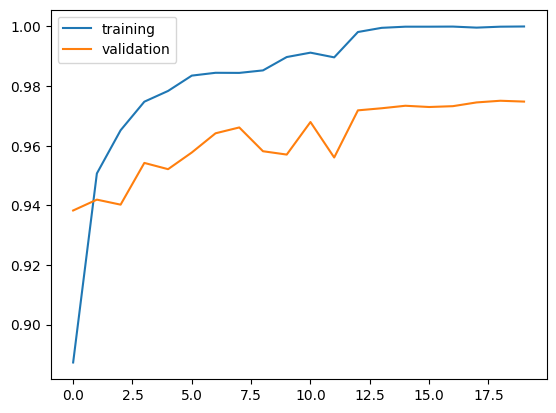

In [18]:
import matplotlib.pyplot as plt
plt.plot(model.history.history['accuracy'],label='training')
plt.plot(model.history.history['val_accuracy'],label='validation')
plt.legend()
plt.show()

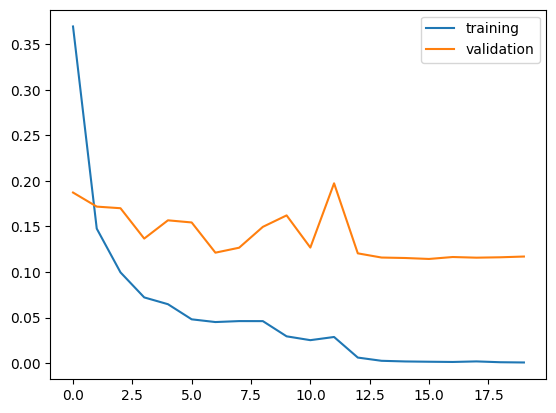

In [19]:

plt.plot(model.history.history['loss'],label='training')
plt.plot(model.history.history['val_loss'],label='validation')
plt.legend()
plt.show()

224/224 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step


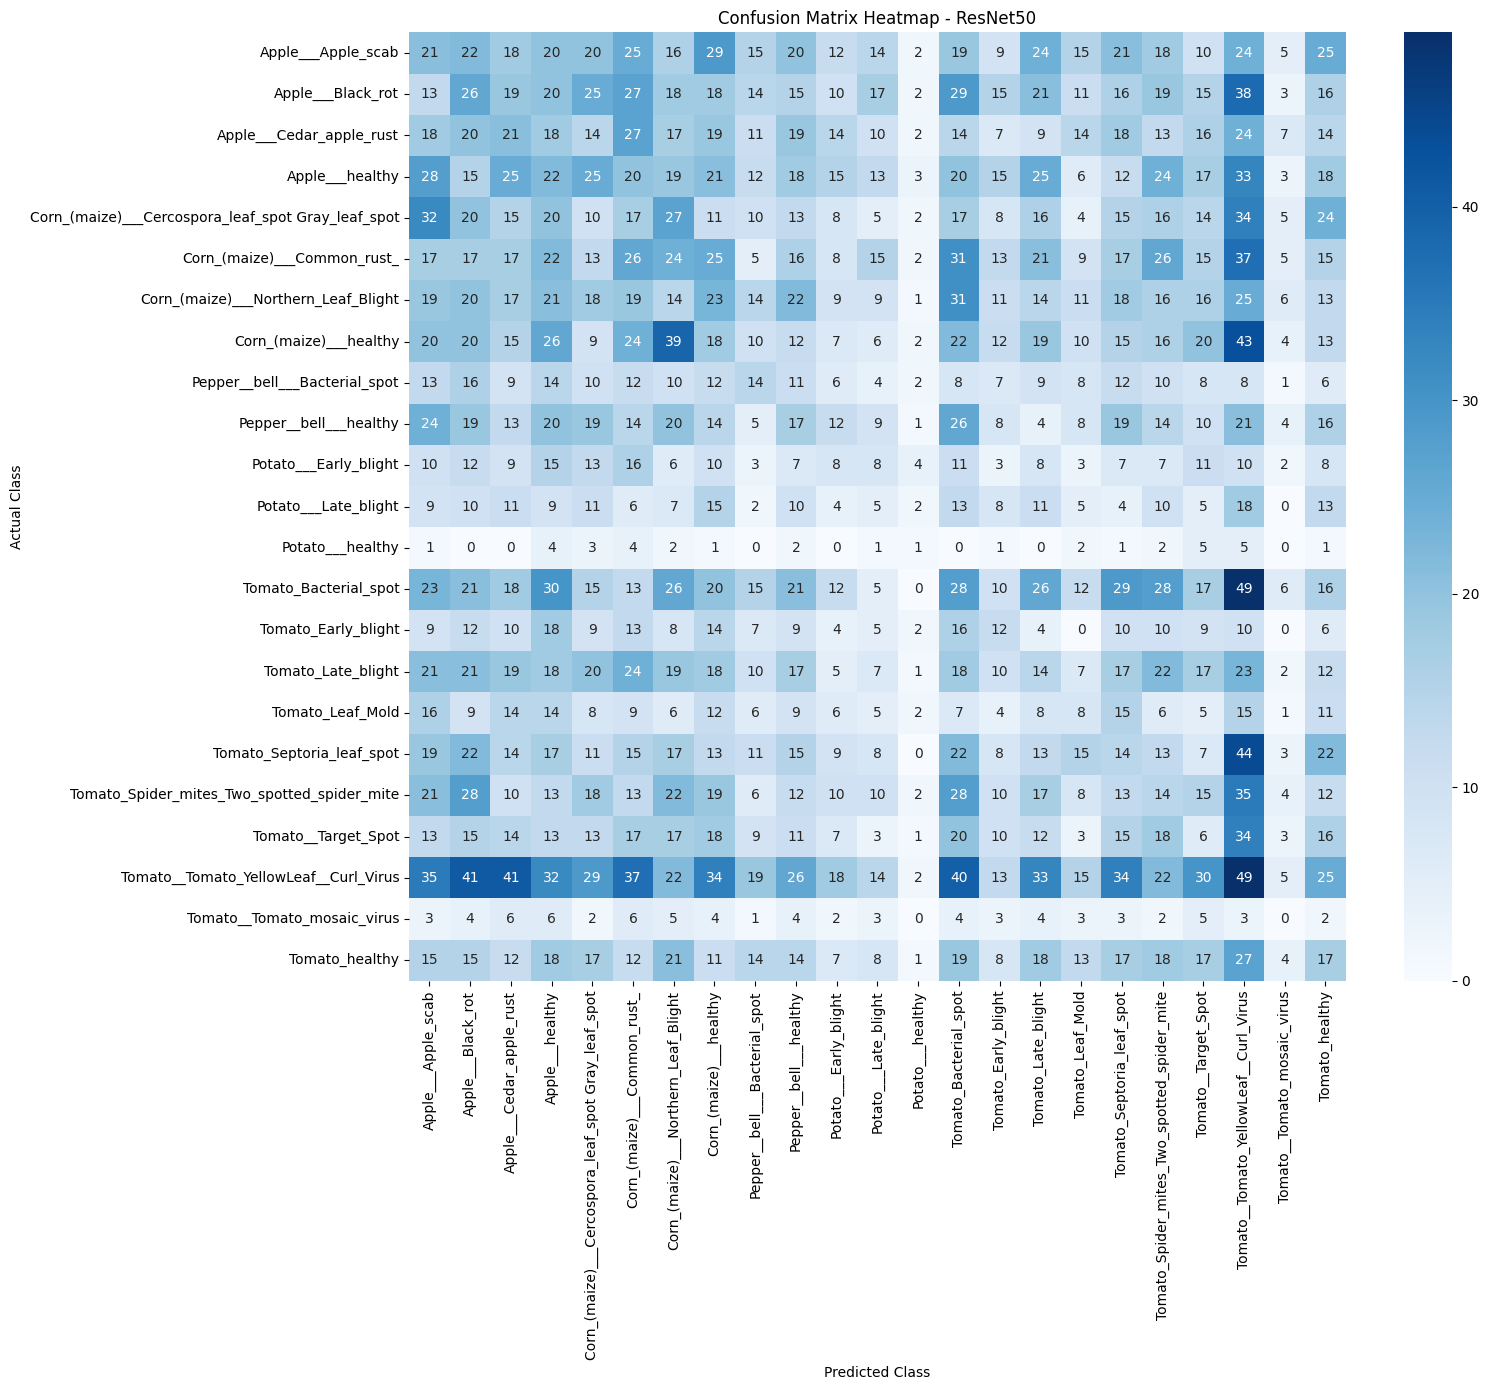

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

class_names = train_data.class_names

y_true = np.concatenate([y.numpy() for x, y in validation_data])
y_pred_prob = model.predict(validation_data)
y_pred = np.argmax(y_pred_prob, axis=1)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(16, 14))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix Heatmap - ResNet50")
plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "resnet50_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

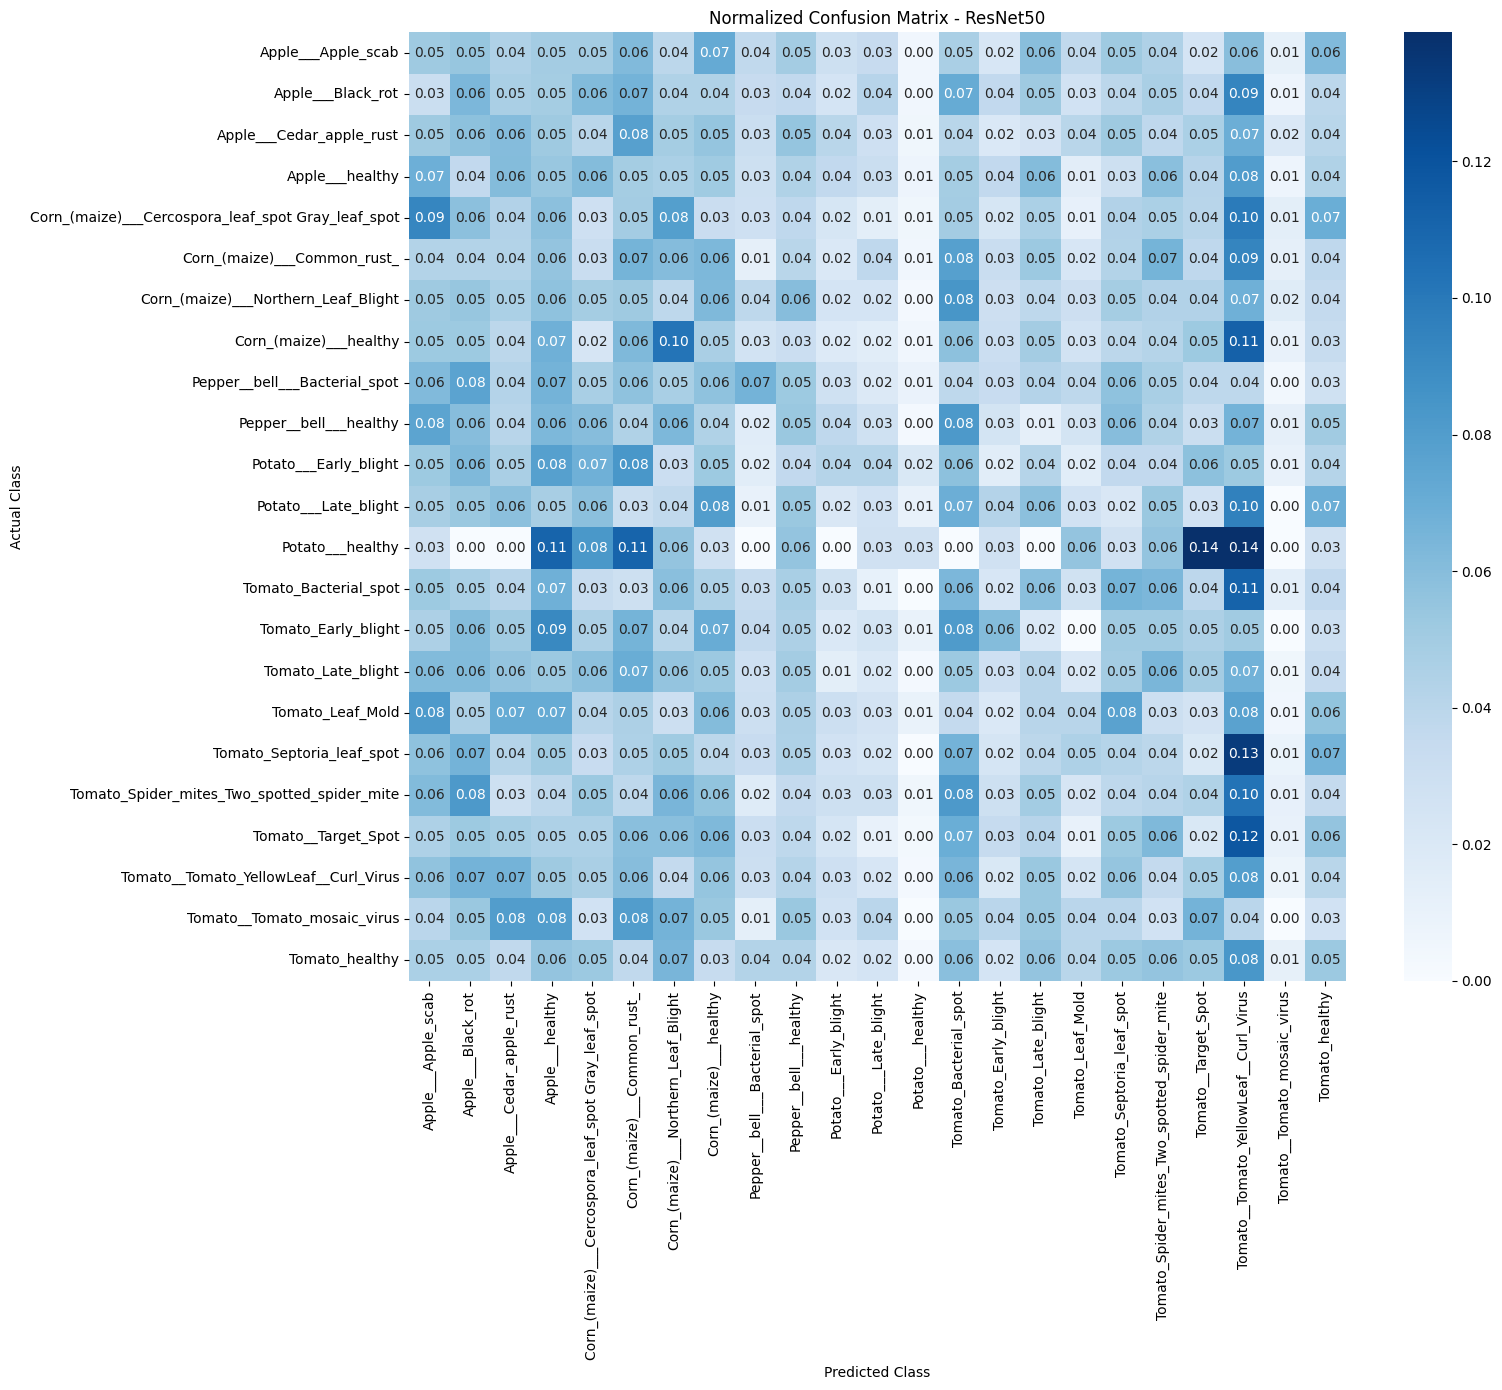

In [22]:
cm_normalized = cm.astype("float") / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(16, 14))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Normalized Confusion Matrix - ResNet50")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "resnet50_normalized_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
!pip install lime -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 19.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [25]:
from lime import lime_image
from skimage.segmentation import mark_boundaries
import matplotlib.pyplot as plt
import numpy as np

In [26]:
explainer = lime_image.LimeImageExplainer()

In [27]:
images, labels = next(iter(validation_data))

image = images[0].numpy().astype(np.uint8)
true_label = labels[0].numpy()

print("True class:", class_names[true_label])

True class: Pepper__bell___healthy


In [28]:
explanation = explainer.explain_instance(
    image,
    classifier_fn=lambda x: model.predict(np.array(x), verbose=0),
    top_labels=5,
    hide_color=0,
    num_samples=1000
)

  0%|          | 0/1000 [00:00<?, ?it/s]

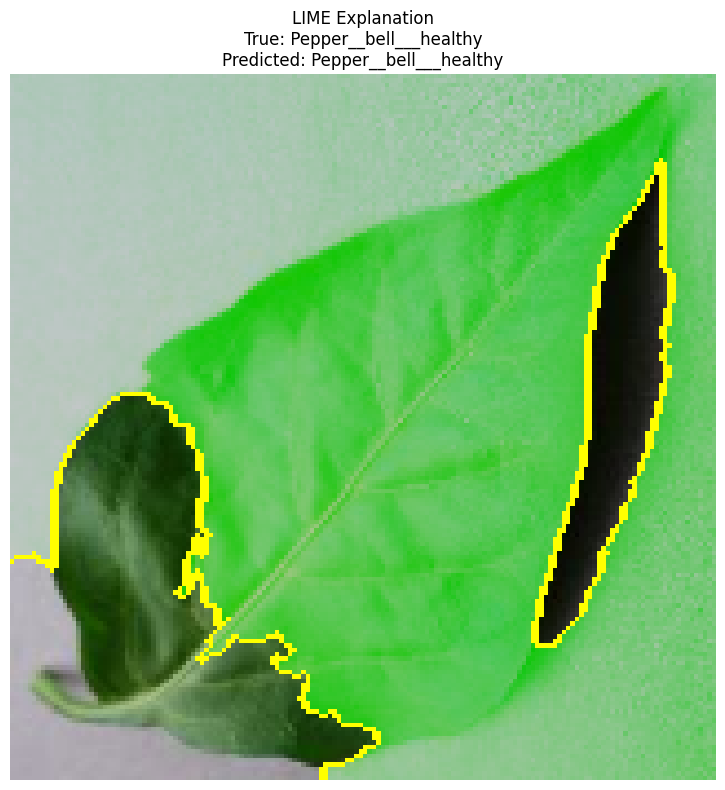

In [29]:
predicted_label = np.argmax(
    model.predict(np.expand_dims(image, axis=0), verbose=0)
)

temp, mask = explanation.get_image_and_mask(
    predicted_label,
    positive_only=False,
    num_features=10,
    hide_rest=False
)

plt.figure(figsize=(8, 8))

plt.imshow(
    mark_boundaries(
        temp / 255.0,
        mask
    )
)

plt.title(
    f"LIME Explanation\n"
    f"True: {class_names[true_label]}\n"
    f"Predicted: {class_names[predicted_label]}"
)

plt.axis("off")
plt.tight_layout()

plt.savefig(
    "lime_explanation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()